In [ ]:
% pip install pandas
% pip install numpy
% pip install matplotlib
% pip install scikit-learn
% pip install progress
% pip install scikit-bio
 
% git clone https://github.com/aleixalcacer/archetypes
% pip install "archetypes/"

In [3]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import time
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [ ]:
otu = pd.read_table("hadza_otu.tsv", index_col=0)
tax = pd.read_table('hadza_tax.tsv', index_col=0)

NameError: name 'pd' is not defined

In [9]:
otu_log = otu.copy()
otu_log = otu_log.map(lambda x: np.log2(x+1))

In [71]:
# ------tax_glom() equivalent------

group = "Family" # Change this to "Kingdom", "Phylum", "Class", "Order", "Family", "Genus",to group by that taxonomic level

# No of uniques => {Kingdom: 1, Phylum: 15, Class: 25, Order: 44, Family: 77, Genus: 305}

grouped_cols = tax[group].unique()

otu_grouped = pd.DataFrame(index=otu.index, columns=grouped_cols)

i = 0
for c in tqdm(otu.columns):
    grp_col = tax[group][c]
    
    if(pd.isnull(otu_grouped[grp_col]).all()):
        otu_grouped[grp_col] = otu[c]
        continue

    otu_grouped[grp_col] = otu_grouped[grp_col] + otu[c]
    # print(f"Processed column ({i+1}/{len(otu.columns)}): {grp_col}")

    i += 1

otu_grouped.columns = otu_grouped.columns.astype(str)


100%|██████████| 3133/3133 [00:00<00:00, 3224.39it/s]


In [72]:
otu_log = otu_grouped.copy()
otu_log = otu_log.map(lambda x: np.log2(x+1))

In [89]:
import scipy.spatial
from skbio.tree import TreeNode
from skbio.diversity import beta_diversity
from skbio.stats.ordination import pcoa
import scipy

# metadata = pd.read_table('metadata.tsv', index_col=0)
FRAC = 0.2
pcoa_data = otu_log.sample(frac=FRAC)

method = scipy.spatial.distance.jensenshannon  #'jensenshannon' # or "jensenshannon", unifrac is problematic
bdiv = beta_diversity(
    method, pcoa_data, ids=pcoa_data.index, pairwise_func=scipy.spatial.distance.pdist
)
# Perform PCoA
pcoa_results = pcoa(bdiv, number_of_dimensions=2)

# Extract the coordinates
pcoa_coordinates = pcoa_results.samples

C:\Users\rayve\AppData\Local\Temp\ipykernel_38752\1046707342.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.xlabel(f"PC1 ({pcoa_results.proportion_explained[0]:.2%} variance explained)")
C:\Users\rayve\AppData\Local\Temp\ipykernel_38752\1046707342.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.ylabel(f"PC2 ({pcoa_results.proportion_explained[1]:.2%} variance explained)")


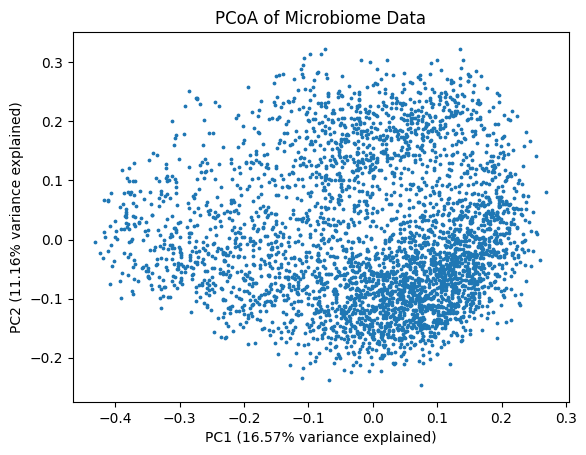

In [90]:
import matplotlib.pyplot as plt

# Create a scatter plot

plt.scatter(pcoa_coordinates['PC1'], pcoa_coordinates['PC2'], s=3)

# Add labels and title
plt.xlabel(f"PC1 ({pcoa_results.proportion_explained[0]:.2%} variance explained)")
plt.ylabel(f"PC2 ({pcoa_results.proportion_explained[1]:.2%} variance explained)")
plt.title("PCoA of Microbiome Data")

# # Add sample labels if desired
# for idx, row in pcoa_coordinates.iterrows():
#     plt.annotate(idx, (row['PC1'], row['PC2']))

plt.show()



In [91]:
from archetypes.numpy._aa_3 import AA_3

col1, col2 = "PC1", "PC2"

AA_data = pcoa_coordinates[[col1, col2]].to_numpy()

method_kwargs = {
    "max_iter_optimizer": 10,
}

N_ARCHETYPES = 3
aa = AA_3(n_archetypes=N_ARCHETYPES, method="pgd", method_kwargs=method_kwargs, random_state=3)


aa.fit(AA_data)

print(aa.archetypes_)

[[ 0.13600928  0.32178067]
 [-0.42681237 -0.0145823 ]
 [ 0.17181468 -0.18085205]]


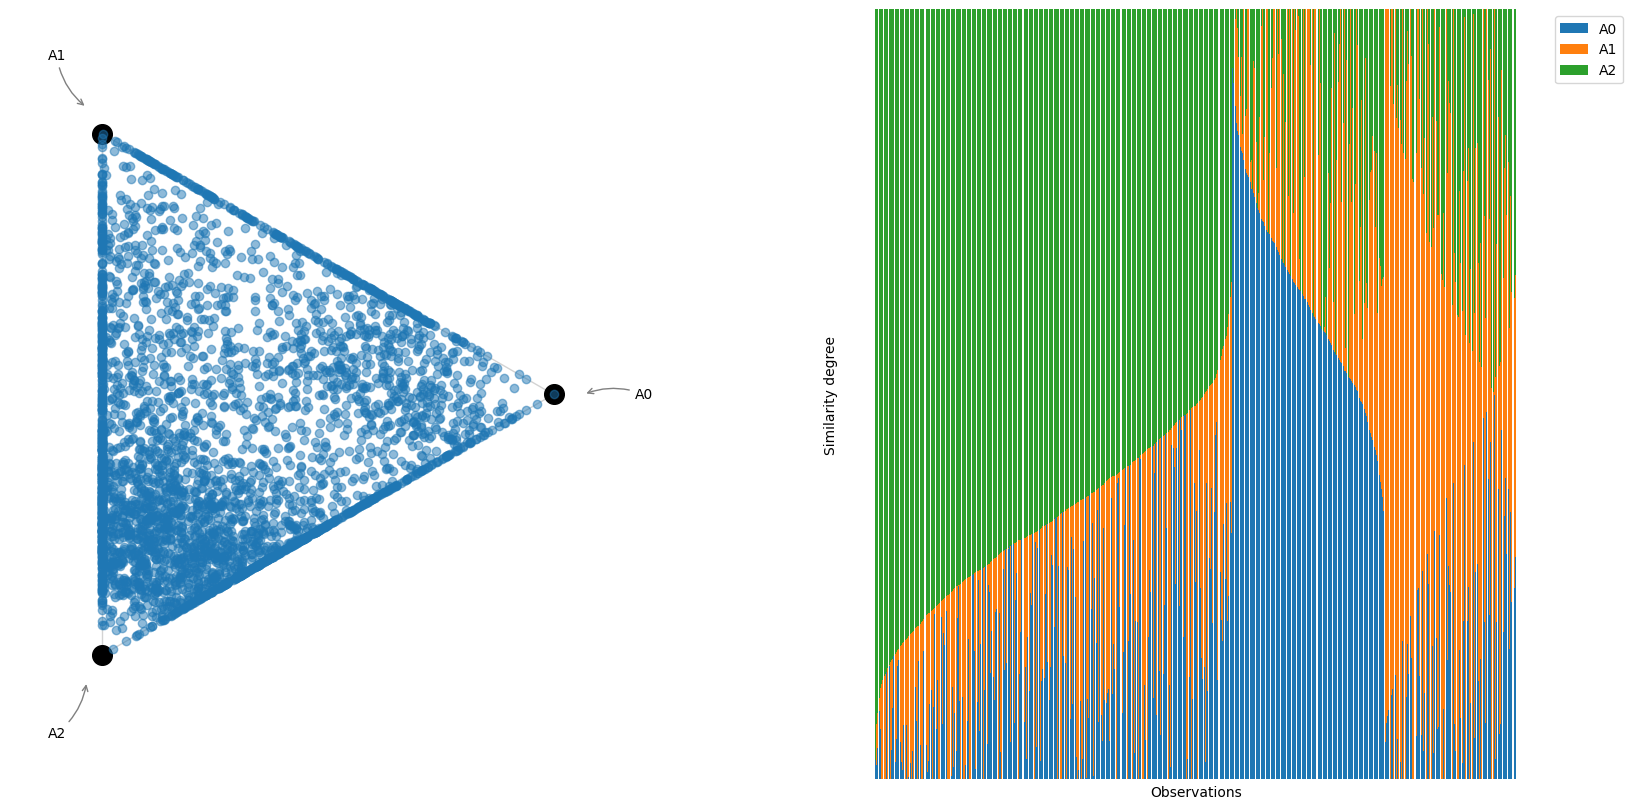

In [92]:
from archetypes.visualization import stacked_bar, simplex
from archetypes.datasets import sort_by_archetype_similarity, permute_dataset

data_sorted, info = sort_by_archetype_similarity(AA_data, [aa.similarity_degree_], aa.archetypes_)

similarity_degree_permuted, _ = permute_dataset(aa.similarity_degree_, info["perms"])

fig, ax = plt.subplots(1, 2, figsize=(20, 10))
simplex(aa.similarity_degree_, alpha=0.5, ax=ax[0], show_vertices=True)
stacked_bar(similarity_degree_permuted, ax=ax[1])

plt.show()


C:\Users\rayve\AppData\Local\Temp\ipykernel_38752\254064229.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.xlabel(f"PC1 ({pcoa_results.proportion_explained[0]:.2%} variance explained)")
C:\Users\rayve\AppData\Local\Temp\ipykernel_38752\254064229.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.ylabel(f"PC2 ({pcoa_results.proportion_explained[1]:.2%} variance explained)")


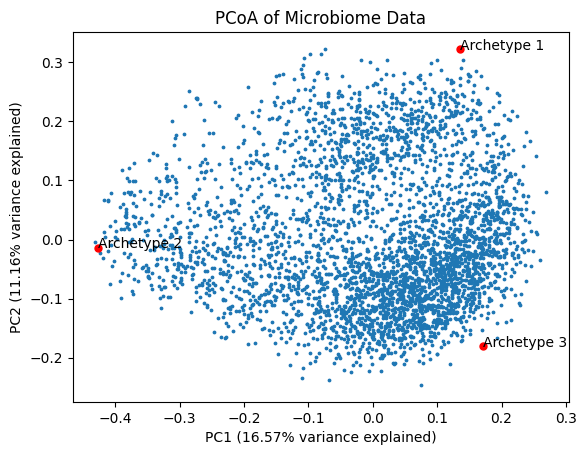

In [93]:
plt.scatter(pcoa_coordinates['PC1'], pcoa_coordinates['PC2'], s=3)

# Add labels and title
plt.xlabel(f"PC1 ({pcoa_results.proportion_explained[0]:.2%} variance explained)")
plt.ylabel(f"PC2 ({pcoa_results.proportion_explained[1]:.2%} variance explained)")
plt.title("PCoA of Microbiome Data")

plt.scatter(aa.archetypes_[:, 0], aa.archetypes_[:, 1], c="red", s=25)
for i, arch in enumerate(aa.archetypes_):
    plt.text(arch[0], arch[1], f"Archetype {i+1}")

# Closest Points to Archetypes
# for i, arch in enumerate(aa.archetypes_):
#     idx = np.argmax(aa.similarity_degree_[:, i])
#     plt.scatter(pcoa_coordinates.iloc[idx]['PC1'], pcoa_coordinates.iloc[idx]['PC2'], c="black", s=25)

plt.show()

In [102]:
otu_aa = pd.DataFrame(aa.similarity_degree_, index=pcoa_coordinates.index, columns=[f"Archetype {i+1}" for i in range(N_ARCHETYPES)])

In [109]:
methodName = method if isinstance(method, str) else "jensenshannon"
otu_aa.to_csv(f"otu_AA_{FRAC}_{group}_{methodName}.tsv", sep="\t")

# Analysis

In [113]:
fName = "otu_AA_0.2_Genus_braycurtis.tsv"
otu_aa = pd.read_table(fName, index_col=0)
hadza_sam = pd.read_table("hadza_sam.tsv", index_col=0)

C:\Users\rayve\AppData\Local\Temp\ipykernel_38752\3461220976.py:3: DtypeWarning: Columns (1,3,4,5,6,7,9,10,11,12,13,14,15,16,17,18,19,20,22,24,25,26,27,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,57,58,61,65,66,67,68,69,70,71,72,73,75,76,77,78,79,80,81,82,83,86,87,88,89,90,91,92,95,97,98,100,101,102,103,105,112,113,114,116,118,120,123,134,135,136,137,138,139,140,141,142,143,146,147,148,149,150,154,155,156,159,161,162,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,194,197,198) have mixed types. Specify dtype option on import or set low_memory=False.
  hadza_sam = pd.read_table("hadza_sam.tsv", index_col=0)


<Axes: >

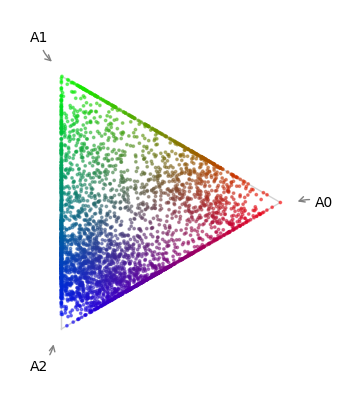

In [114]:
color = otu_aa.to_numpy()  # Visualization Specific

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
simplex(aa.similarity_degree_, alpha=0.5, ax=ax, c=color, s=3)

In [96]:
arch_idx = [np.argmin(otu_aa[arch]) for arch in otu_aa.columns]

arch_ID = [hadza_sam.index[i] for i in arch_idx]
print(f"Closest Archetypes: {arch_ID}")


Closest Archetypes: ['Bgsng7155.m10', '3100391', 'Bgsng7096.m56']


In [97]:
summary_cols = ["age_months", "location", "GENDER"]  # Dataset Specific
summary = hadza_sam.loc[arch_ID, summary_cols]
print(summary)

               age_months    location GENDER
SampleID                                    
Bgsng7155.m10    9.100000  Bangladesh      2
3100391         25.333333         RUS    NaN
Bgsng7096.m56   55.200000  Bangladesh      2


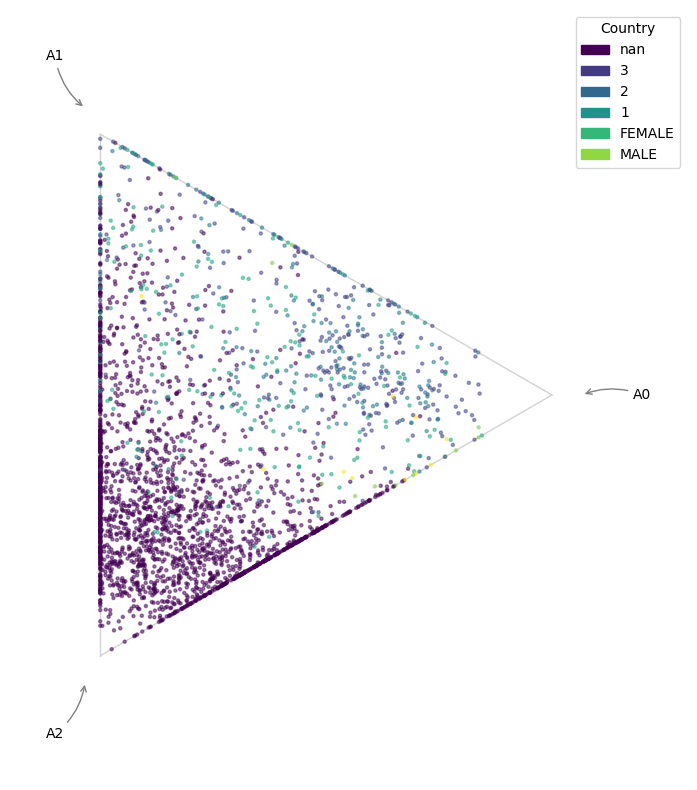

In [99]:
from matplotlib.patches import Patch
import matplotlib.cm as cm

filter_col = "location"

present_idx = otu_aa.index.intersection(hadza_sam.index)
present_points = otu_aa.loc[present_idx]
color_dataset = hadza_sam.loc[present_idx, filter_col]  # Visualization Specific
unique_colors = {c: i/len(color_dataset.unique()) for i, c in enumerate(color_dataset.unique())}
color = color_dataset.map(unique_colors)


fig, ax = plt.subplots(1, 1, figsize=(10, 10))
simplex(present_points, alpha=0.5, ax=ax, c=color, cmap = "viridis", s=5)


legend_patches = [
    Patch(color=cm.viridis(unique_colors[c]), label=c)
    for c in unique_colors
]

# Add the legend to the plot
ax.legend(handles=legend_patches, title="Country", loc='upper right')



# OLD STUFF

Percentage of variance explained by the first two components: 15.20%


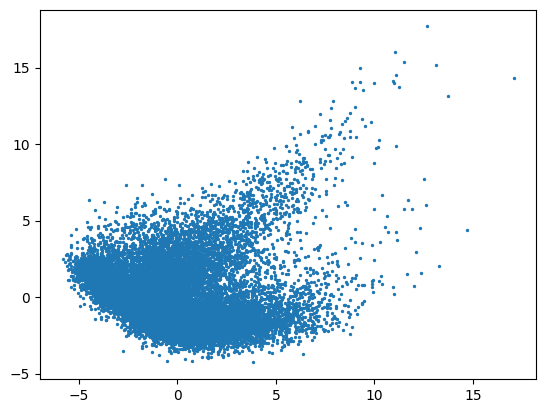

In [9]:
pca_data = otu_grouped_log # Or otu itself

pca_data = StandardScaler().fit_transform(pca_data)

pca = PCA(n_components=2)
pca.fit(pca_data)

otu_pca = pca.transform(pca_data)

variance_explained = sum(pca.explained_variance_ratio_) * 100

print(f"Percentage of variance explained by the first two components: {variance_explained:.2f}%")

plt.scatter(otu_pca[:, 0], otu_pca[:, 1], s=2)
plt.show()



In [ ]:
group = "Family" # Change this to "Kingdom", "Phylum", "Class", "Order", "Family", "Genus",to group by that taxonomic level

# No of uniques => {Kingdom: 1, Phylum: 15, Class: 25, Order: 44, Family: 77, Genus: 305}

grouped_cols = tax[group].unique()

otu_grouped = pd.DataFrame(index=otu.index, columns=grouped_cols)

i = 0
for c in tqdm(otu.columns):
    grp_col = tax[group][c]
    
    if(pd.isnull(otu_grouped[grp_col]).all()):
        otu_grouped[grp_col] = otu[c]
        continue

    otu_grouped[grp_col] = otu_grouped[grp_col] + otu[c]
    # print(f"Processed column ({i+1}/{len(otu.columns)}): {grp_col}")

    i += 1

otu_grouped.columns = otu_grouped.columns.astype(str)


100%|██████████| 3133/3133 [00:00<00:00, 4778.56it/s]


In [3]:
otu_grouped_log = otu_grouped.copy()
otu_grouped_log = otu_grouped_log.map(lambda x: np.log2(x+1))

# print(otu_grouped_log)

NameError: name 'otu_grouped' is not defined

In [ ]:
# !jupyter nbconvert --to python AA_GHG_291024.ipynb

[NbConvertApp] Converting notebook AA_GHG_291024.ipynb to python
[NbConvertApp] Writing 7526 bytes to AA_GHG_291024.py
